# RoBERTa-base · Toxic Comment Classification (Fine-tuning)

**COMP6713 Group Project — Part C: Pre-trained Model + Fine-tuning**

This notebook fine-tunes `roberta-base` on our cleaned **6w (≈64k)** social-media comment dataset for **binary toxicity classification** (`0 = non-toxic`, `1 = toxic`).

## What this notebook does (plain English)
1. **Loads** the lightly-cleaned train / val / test splits.
2. **Tokenises** the text with RoBERTa's tokenizer (handles sub-words, punctuation, emojis).
3. **Fine-tunes** `roberta-base` with a classification head for **3 epochs**.
4. Uses **class-weighted cross-entropy** because the dataset is imbalanced (~91% non-toxic / ~9% toxic).
5. **Evaluates** on (a) the held-out test set and (b) our own `new_200.csv` manual-annotation set.
6. Performs **qualitative error analysis** — looks at the worst false positives / false negatives.
7. **Saves** the fine-tuned model and a small `predict()` helper for the Gradio demo / CLI tools later.

## Why RoBERTa-base?
- Same architecture as BERT but trained on **10× more data** with a better objective → consistently higher F1 on toxicity benchmarks.
- 125M parameters → fits easily on a free Colab T4 GPU.
- Lightly-cleaned text preserves negation words and punctuation, which RoBERTa can exploit through its attention mechanism.

## Runtime
- Hardware: **Colab T4 GPU** (free tier)
- ~3 epochs × 51k training samples ≈ **20–30 minutes total**.

## 1. Environment setup

Install the required libraries. On Colab the base image already ships with `torch` and most utilities, so the install step is fast (~30 s).

In [1]:
!pip install -q -U transformers==4.44.2 datasets==2.21.0 evaluate==0.4.3 accelerate==0.34.2 scikit-learn seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 112.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 527.3/527.3 kB 42.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.4/324.4 kB 35.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 131.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.6/177.6 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 34.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 122.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.6.1 which is incompatible.


In [2]:
import os, random, json, warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, roc_auc_score,
)
from sklearn.utils.class_weight import compute_class_weight

from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding,
    set_seed,
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
set_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Torch: 2.10.0+cu128 | CUDA available: True
GPU: Tesla T4


## 2. Paths & data loading

We expect the cleaned dataset to live on Google Drive. Mount Drive and point the paths to the **`pre-trained model/6w data`** folder (lightly cleaned text — punctuation, negation words and casing preserved).

> If you are not on Colab, just edit `DATA_DIR` to a local path and skip the `drive.mount` cell.

In [4]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR    = "/content/drive/MyDrive/6713groupwork/MISC/data"
    MANUAL_PATH = "/content/drive/MyDrive/6713groupwork/MISC/data/manual_annotation_200.csv"
    OUTPUT_DIR  = "/content/drive/MyDrive/6713groupwork/CODE/model"
except ModuleNotFoundError:
    # Local layout (team submission): CODE/ and MISC/ are siblings
    DATA_DIR    = "../MISC/data"
    MANUAL_PATH = "../MISC/data/manual_annotation_200.csv"
    OUTPUT_DIR  = "./model"

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("DATA_DIR  =", DATA_DIR)
print("MANUAL    =", MANUAL_PATH)
print("OUTPUT_DIR=", OUTPUT_DIR)

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
val_df   = pd.read_csv(os.path.join(DATA_DIR, "val.csv"))
test_df  = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    df.dropna(subset=["cleaned_text", "toxic"], inplace=True)
    df["cleaned_text"] = df["cleaned_text"].astype(str)
    df["toxic"] = df["toxic"].astype(int)
    print(f"{name:5s} | n={len(df):6d} | toxic ratio={df['toxic'].mean():.3%}")

train_df.head(3)

train | n= 51128 | toxic ratio=9.247%
val   | n=  6391 | toxic ratio=9.247%
test  | n=  6391 | toxic ratio=9.247%


,cleaned_text,toxic
0,i am trying to get an article up that covers a...,0
1,"subcategories i removed the category, scientif...",0
2,"mr zenger, there is no evidence that suggest t...",0


### 2.1 Quick EDA — class balance & text length

We need to know:
- **Class imbalance** → drives our use of class-weighted loss.
- **Token-length distribution** → drives the choice of `max_length` (longer = more memory + slower).

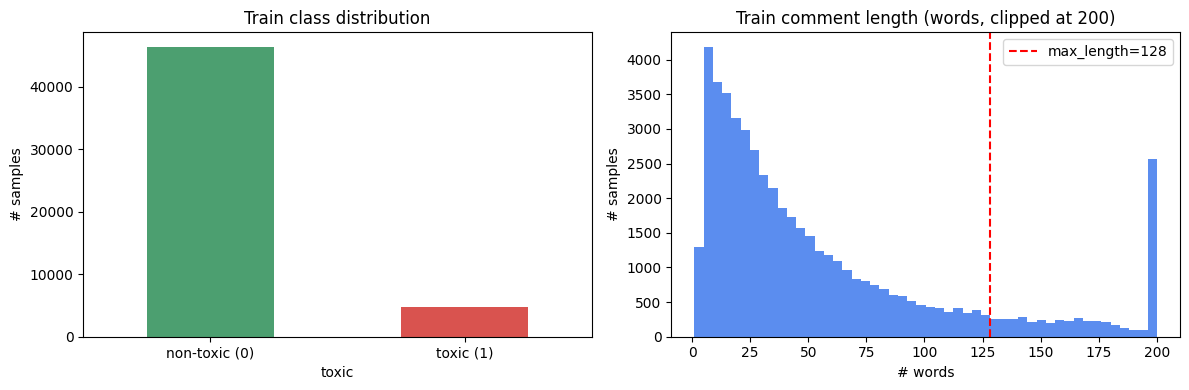

95th percentile word count: 197
99th percentile word count: 505


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train_df["toxic"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["#4C9F70", "#D9534F"]
)
axes[0].set_title("Train class distribution")
axes[0].set_xticklabels(["non-toxic (0)", "toxic (1)"], rotation=0)
axes[0].set_ylabel("# samples")

word_counts = train_df["cleaned_text"].str.split().str.len()
axes[1].hist(word_counts.clip(upper=200), bins=50, color="#5B8DEF")
axes[1].axvline(128, color="red", ls="--", label="max_length=128")
axes[1].set_title("Train comment length (words, clipped at 200)")
axes[1].set_xlabel("# words"); axes[1].set_ylabel("# samples"); axes[1].legend()

plt.tight_layout(); plt.show()
print(f"95th percentile word count: {word_counts.quantile(0.95):.0f}")
print(f"99th percentile word count: {word_counts.quantile(0.99):.0f}")

## 3. Tokenisation

We use the official `roberta-base` tokenizer. Key choices:

| Hyperparameter | Value | Reason |
|---|---|---|
| `max_length` | **128** | covers ~95% of comments without truncation; halves GPU memory vs 256 |
| `truncation` | `True` | longer comments get tail-cut |
| `padding` | dynamic via `DataCollatorWithPadding` | only pad to longest sample in each batch → big speed-up |

In [6]:
MODEL_NAME = "roberta-base"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_hf(df):
    return Dataset.from_pandas(
        df[["cleaned_text", "toxic"]].rename(columns={"toxic": "labels"}),
        preserve_index=False,
    )

raw_ds = {
    "train": to_hf(train_df),
    "val":   to_hf(val_df),
    "test":  to_hf(test_df),
}

def tokenize_batch(batch):
    return tokenizer(
        batch["cleaned_text"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

tokenized_ds = {
    split: ds.map(tokenize_batch, batched=True, remove_columns=["cleaned_text"])
    for split, ds in raw_ds.items()
}
tokenized_ds["train"]

Dataset({
    features: ['labels', 'input_ids', 'attention_mask'],
    num_rows: 51128
})

## 4. Handling class imbalance — class-weighted loss

Toxic comments are only ~9% of the data. With ordinary cross-entropy the model would minimise loss simply by always predicting "non-toxic" → 91% accuracy but **0% recall** on the class we actually care about.

We therefore **weight each class inversely to its frequency** so that mistakes on the rare toxic class are punished more strongly. This is mathematically equivalent to oversampling but **does not slow down training** and is simpler than focal loss.

In [7]:
y_train = train_df["toxic"].values
class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train,
)
CLASS_WEIGHTS = torch.tensor(class_weights_np, dtype=torch.float32, device=DEVICE)
print("Class weights (non-toxic, toxic):", CLASS_WEIGHTS.tolist())

Class weights (non-toxic, toxic): [0.5509482622146606, 5.406937599182129]


## 5. Custom `Trainer` and metric function

`WeightedTrainer` overrides `compute_loss` to use the class weights computed above. Everything else (gradient accumulation, fp16, eval loop) is inherited from Hugging Face's `Trainer`.

The metric function reports **accuracy, macro-F1, toxic-class precision/recall/F1, and ROC-AUC**. We will optimise model selection on **toxic-class F1**, the metric the assignment cares about most.

In [8]:
import torch.nn as nn

class WeightedTrainer(Trainer):
    """Trainer that uses class-weighted cross-entropy."""
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)
        loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    preds = probs.argmax(axis=-1)

    acc = accuracy_score(labels, preds)
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    p_tox, r_tox, f1_tox, _ = precision_recall_fscore_support(
        labels, preds, labels=[1], average=None, zero_division=0
    )
    try:
        auc = roc_auc_score(labels, probs[:, 1])
    except ValueError:
        auc = float("nan")

    return {
        "accuracy": acc,
        "f1_macro": f1_macro,
        "precision_macro": p_macro,
        "recall_macro": r_macro,
        "f1_toxic": f1_tox[0],
        "precision_toxic": p_tox[0],
        "recall_toxic": r_tox[0],
        "roc_auc": auc,
    }

## 6. Training configuration

| Hyperparameter | Value | Reason |
|---|---|---|
| Optimizer | AdamW (HF default) | standard for transformers |
| Learning rate | `2e-5` | safe default for RoBERTa fine-tuning |
| Warmup ratio | `0.1` | short LR warm-up stabilises early steps |
| Weight decay | `0.01` | regularisation, HF default |
| Batch size (train/eval) | 32 / 64 | fits T4 16 GB with `max_length=128` + fp16 |
| Epochs | 3 | RoBERTa typically converges in 2-4 epochs on this task |
| Mixed precision | **fp16** | ~2× speed-up on T4 |
| Best-model criterion | `f1_toxic` | metric we care about |
| Eval/save strategy | per-epoch | small enough that we can keep all checkpoints |

In [9]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "non-toxic", 1: "toxic"},
    label2id={"non-toxic": 0, "toxic": 1},
)

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=3,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_toxic",
    greater_is_better=True,
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    report_to="none",
    seed=SEED,
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["val"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
print("Trainer ready.")

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Trainer ready.


## 7. Train

Expected runtime on Colab T4 ≈ **20-30 minutes** for 3 epochs.

In [10]:
train_result = trainer.train()
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)
print("Best model saved to:", OUTPUT_DIR)
train_result.metrics

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Precision Macro,Recall Macro,F1 Toxic,Precision Toxic,Recall Toxic,Roc Auc
1,0.285400,0.328451,0.950243,0.861766,0.839615,0.888247,0.751174,0.698690,0.812183,0.974930
2,0.222700,0.293539,0.953215,0.870833,0.846369,0.900522,0.767677,0.709770,0.835871,0.977018
3,0.124900,0.387796,0.954311,0.872891,0.850449,0.899606,0.771160,0.718248,0.832487,0.976321


Best model saved to: /content/drive/MyDrive/6713groupwork/models/roberta_base_6w


{'train_runtime': 1242.9166,
 'train_samples_per_second': 123.407,
 'train_steps_per_second': 3.857,
 'total_flos': 1.008752986253376e+16,
 'train_loss': 0.2502936833492656,
 'epoch': 3.0}

## 8. Quantitative evaluation

### 8.1 On the held-out test set (~6.4k samples, same distribution as training)


=== TEST (6w in-distribution) ===
  accuracy          : 0.9567
  f1_macro          : 0.8783
  precision_macro   : 0.8582
  recall_macro      : 0.9017
  f1_toxic          : 0.7807
  precision_toxic   : 0.7336
  recall_toxic      : 0.8342
  roc_auc           : 0.9759

Classification report:
              precision    recall  f1-score   support

   non-toxic     0.9829    0.9691    0.9760      5800
       toxic     0.7336    0.8342    0.7807       591

    accuracy                         0.9567      6391
   macro avg     0.8582    0.9017    0.8783      6391
weighted avg     0.9598    0.9567    0.9579      6391



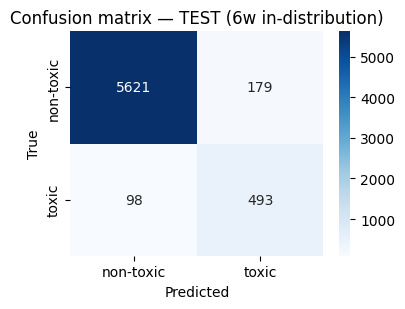

In [11]:
def evaluate_on(dataset, df, split_name="test"):
    """Run trainer.predict and produce metrics + a results dataframe with raw text + preds."""
    pred_out = trainer.predict(dataset)
    logits = pred_out.predictions
    probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    preds = probs.argmax(axis=-1)
    labels = pred_out.label_ids

    metrics = compute_metrics((logits, labels))
    print(f"\n=== {split_name} ===")
    for k, v in metrics.items():
        print(f"  {k:18s}: {v:.4f}")

    print("\nClassification report:")
    print(classification_report(labels, preds, target_names=["non-toxic", "toxic"], digits=4))

    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(4, 3.2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["non-toxic", "toxic"],
                yticklabels=["non-toxic", "toxic"])
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(f"Confusion matrix — {split_name}")
    plt.tight_layout(); plt.show()

    out = df.reset_index(drop=True).copy()
    out["pred"] = preds
    out["prob_toxic"] = probs[:, 1]
    return metrics, out

test_metrics, test_results = evaluate_on(tokenized_ds["test"], test_df, "TEST (6w in-distribution)")

### 8.2 On the **manual annotation set** (`new_200.csv`, ~232 comments)

This set was hand-labelled by two annotators (Cohen's κ = 0.73 after refinement) and is **out-of-distribution** — it contains:
- Real Reddit / Instagram / YouTube / X comments
- Sarcasm, attitude shifts, emerging slang
- ~38% toxic ratio (much higher than the ~9% in training data)

Performance here is the **honest measure** of how the model handles realistic, hard-to-classify content.

Loaded manual_annotation_200.csv with encoding=cp1252, n=232
Toxic ratio in manual set: 37.931%



=== MANUAL_200 (out-of-distribution) ===
  accuracy          : 0.6983
  f1_macro          : 0.6476
  precision_macro   : 0.6855
  recall_macro      : 0.6443
  f1_toxic          : 0.5139
  precision_toxic   : 0.6607
  recall_toxic      : 0.4205
  roc_auc           : 0.6881

Classification report:
              precision    recall  f1-score   support

   non-toxic     0.7102    0.8681    0.7812       144
       toxic     0.6607    0.4205    0.5139        88

    accuracy                         0.6983       232
   macro avg     0.6855    0.6443    0.6476       232
weighted avg     0.6914    0.6983    0.6798       232



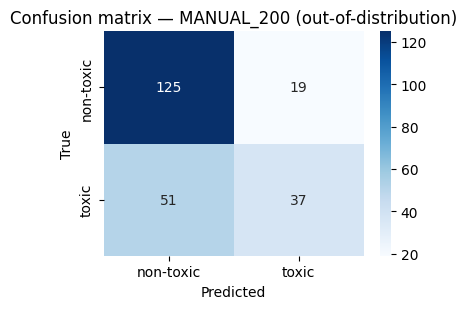

In [12]:
manual_df = None
for enc in ("utf-8", "cp1252", "latin-1"):
    try:
        manual_df = pd.read_csv(MANUAL_PATH, encoding=enc)
        print(f"Loaded manual_annotation_200.csv with encoding={enc}, n={len(manual_df)}")
        break
    except UnicodeDecodeError:
        continue
assert manual_df is not None, "Could not read manual annotation file with any encoding."

manual_df = manual_df.dropna(subset=["cleaned_text", "toxic"]).reset_index(drop=True)
manual_df["cleaned_text"] = manual_df["cleaned_text"].astype(str)
manual_df["toxic"] = manual_df["toxic"].astype(int)
print(f"Toxic ratio in manual set: {manual_df['toxic'].mean():.3%}")

manual_ds = to_hf(manual_df).map(tokenize_batch, batched=True, remove_columns=["cleaned_text"])
manual_metrics, manual_results = evaluate_on(manual_ds, manual_df, "MANUAL_200 (out-of-distribution)")

### 8.3 Side-by-side summary table

The table below is what should be copied into the report's results section. It compares this model's performance on (a) the in-distribution test split and (b) the harder manual-annotation set.

In [13]:
summary = pd.DataFrame(
    {"test_6w": test_metrics, "manual_200": manual_metrics}
).round(4)
summary.to_csv(os.path.join(OUTPUT_DIR, "roberta_base_summary_metrics.csv"))
summary

,test_6w,manual_200
accuracy,0.9567,0.6983
f1_macro,0.8783,0.6476
precision_macro,0.8582,0.6855
recall_macro,0.9017,0.6443
f1_toxic,0.7807,0.5139
precision_toxic,0.7336,0.6607
recall_toxic,0.8342,0.4205
roc_auc,0.9759,0.6881


## 9. Qualitative analysis — where does the model fail?

We look at the **most confident wrong predictions** in both directions:
- **False positives (FP)** — non-toxic comments predicted as toxic with high confidence. Often: strong opinions, profanity used non-aggressively, sarcasm, religious / political language.
- **False negatives (FN)** — toxic comments the model thought were safe. Often: implicit toxicity, dog-whistles, coded slurs, sarcasm masking aggression.

These categories should be discussed in the **report's qualitative analysis section**.

In [14]:
def show_errors(results_df, name, top_k=10):
    fp = (results_df[(results_df["toxic"] == 0) & (results_df["pred"] == 1)]
          .sort_values("prob_toxic", ascending=False).head(top_k))
    fn = (results_df[(results_df["toxic"] == 1) & (results_df["pred"] == 0)]
          .sort_values("prob_toxic", ascending=True).head(top_k))

    print(f"\n=== Top {top_k} FALSE POSITIVES — {name} (model wrongly says TOXIC) ===")
    for _, r in fp.iterrows():
        print(f"  [p_tox={r.prob_toxic:.3f}]  {r.cleaned_text[:200]}")

    print(f"\n=== Top {top_k} FALSE NEGATIVES — {name} (model misses real toxicity) ===")
    for _, r in fn.iterrows():
        print(f"  [p_tox={r.prob_toxic:.3f}]  {r.cleaned_text[:200]}")
    return fp, fn

fp_test, fn_test     = show_errors(test_results,   "TEST 6w",    top_k=10)
fp_man,  fn_man      = show_errors(manual_results, "MANUAL_200", top_k=10)


=== Top 10 FALSE POSITIVES — TEST 6w (model wrongly says TOXIC) ===
  [p_tox=0.999]  cunt editing you should be added to the list i was creating, ergo you are a cunt.
  [p_tox=0.999]  adam rose john cena lover why do you defend pg wrestling when you don't even know what the fuck wwe is about? why defend a phony wrestler like john cena and a faggot ass queer who likes to have a fist
  [p_tox=0.999]  bongwarrior my dearest bongwarrior, how the fuck are you allowed to edit anything on this site with a name like bongwarrior, how? honestly, how? yours sincerely, garfunkel felchmaster.
  [p_tox=0.999]  go away, you annoying vandal.
  [p_tox=0.999]  vandalism, douching, and faggotry are not tolerated on this website.
  [p_tox=0.999]  hi luke's ass. how you doin' ?
  [p_tox=0.999]  please see a picture of my balls. i am uninterested in your little internet power games. you can eat a dick. you are way late, seeing as that other dick already both berated me rudely and erased my ar
  [p_tox=0.99

In [15]:
errors = pd.concat([
    fp_test.assign(split="test_6w",    error="FP"),
    fn_test.assign(split="test_6w",    error="FN"),
    fp_man.assign( split="manual_200", error="FP"),
    fn_man.assign( split="manual_200", error="FN"),
])
errors_path = os.path.join(OUTPUT_DIR, "roberta_base_error_samples.csv")
errors.to_csv(errors_path, index=False)
print("Saved error samples to:", errors_path)

Saved error samples to: /content/drive/MyDrive/6713groupwork/models/roberta_base_6w/roberta_base_error_samples.csv


In [16]:
from transformers import pipeline

clf_pipe = pipeline(
    "text-classification",
    model=OUTPUT_DIR,
    tokenizer=OUTPUT_DIR,
    device=0 if torch.cuda.is_available() else -1,
    truncation=True,
    max_length=MAX_LENGTH,
    top_k=None,
)

def predict(texts, threshold: float = 0.5):
    """Return a list of dicts: {text, label, prob_toxic}.
    `threshold` lets the team tune precision/recall after training (e.g. raise to 0.7
    for a stricter toxic flag in the demo)."""
    if isinstance(texts, str):
        texts = [texts]
    raw = clf_pipe(texts, batch_size=32)
    out = []
    for text, scores in zip(texts, raw):
        prob_toxic = next(s["score"] for s in scores if s["label"] == "toxic")
        label = "toxic" if prob_toxic >= threshold else "non-toxic"
        out.append({"text": text, "label": label, "prob_toxic": float(prob_toxic)})
    return out

predict([
    "I love this community, you guys are great!",
    "you are an idiot and should shut up",
    "Not bad, actually pretty interesting take.",
])

[{'text': 'I love this community, you guys are great!',
  'label': 'non-toxic',
  'prob_toxic': 0.000833381898701191},
 {'text': 'you are an idiot and should shut up',
  'label': 'toxic',
  'prob_toxic': 0.9991376399993896},
 {'text': 'Not bad, actually pretty interesting take.',
  'label': 'non-toxic',
  'prob_toxic': 0.0004868374380748719}]